
--------------------------------------------------
A. DATA LOADING & INITIAL INSPECTION
--------------------------------------------------
Total rows and columns: (200, 5)

Column names: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Data types:
 CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object

First 5 rows:
    CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Last 5 rows:
      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
195      

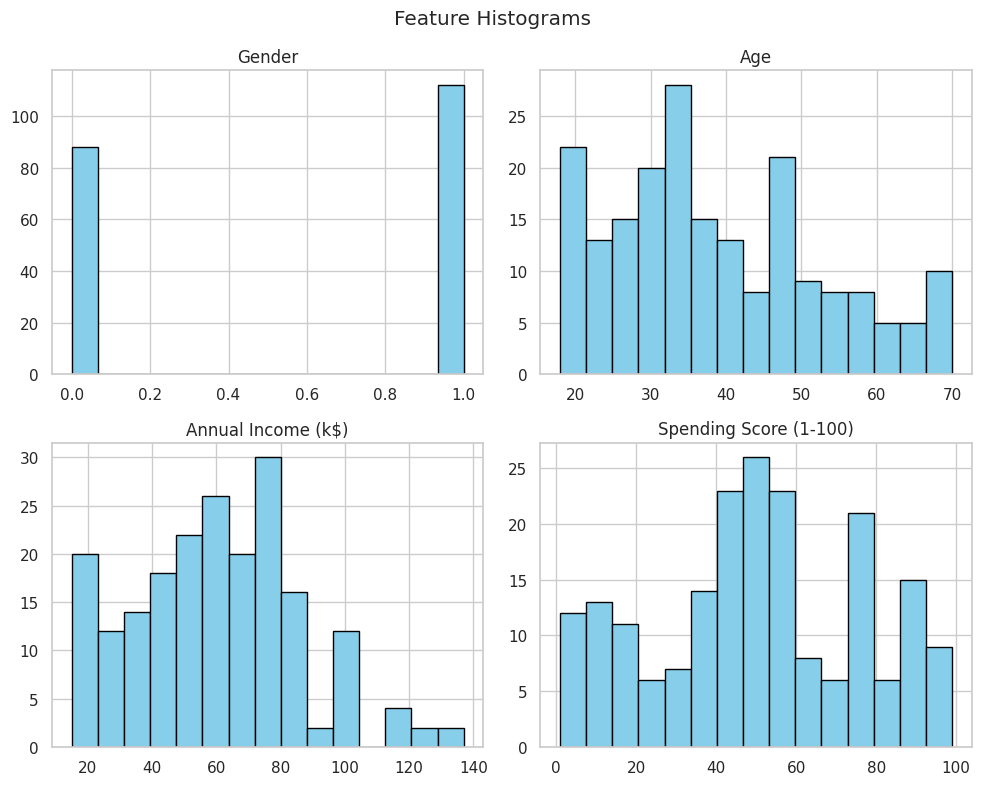

Observation: Income and spending scores show spread-out distributions across customers.


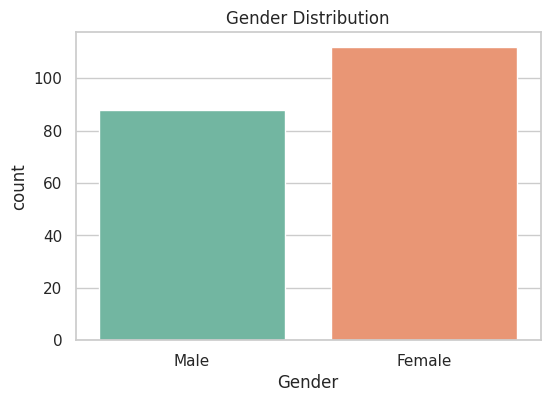

Observation: Female customers account for a slightly larger portion.


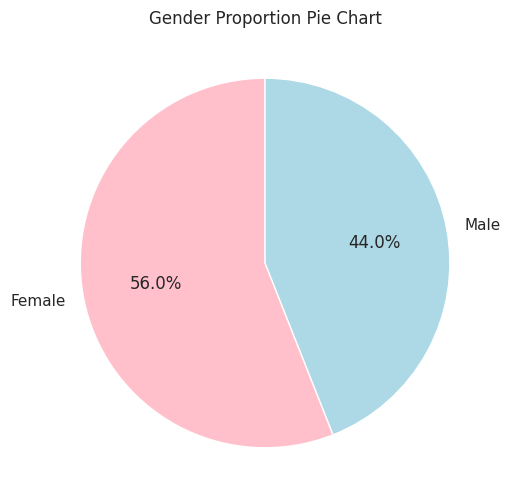

Observation: Validates the exact percentage split between genders.


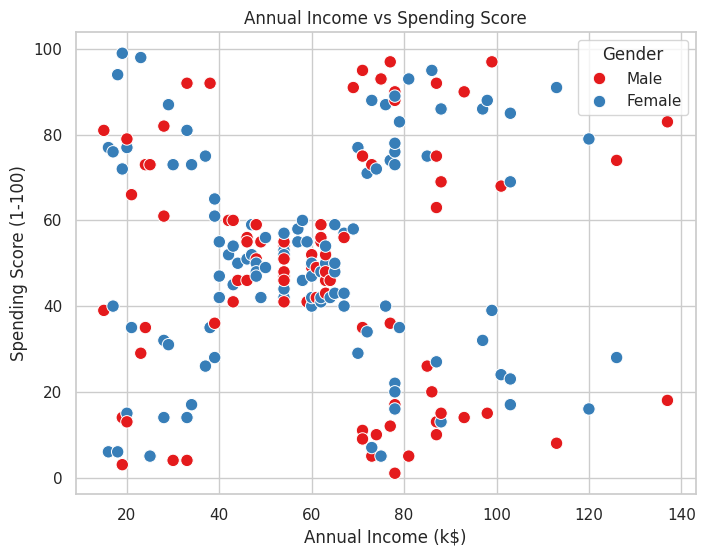

Observation: Clear natural groupings are visible even before running any model.


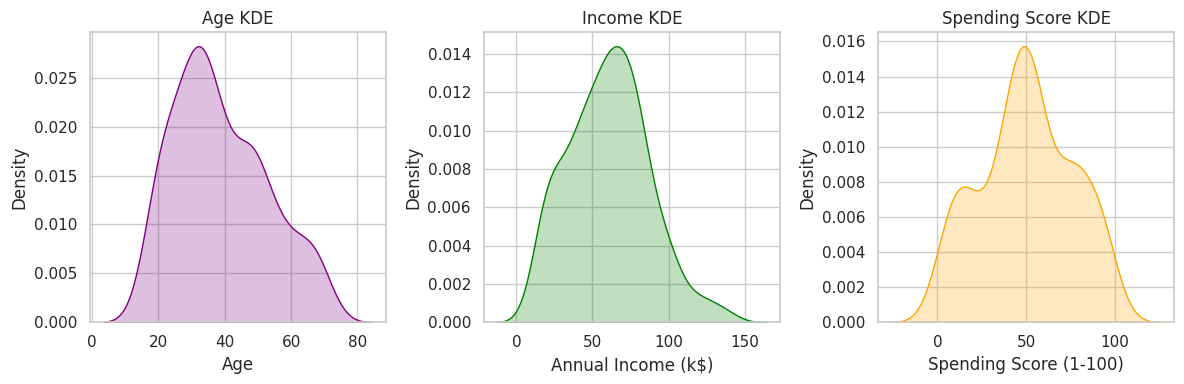

Observation: Highlights density peaks across different metrics.


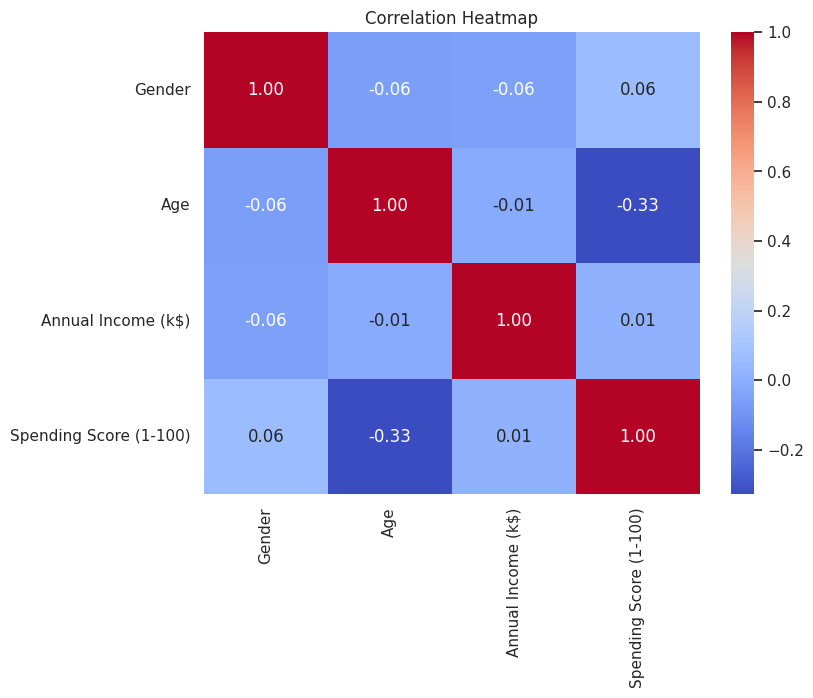

Observation: Age exhibits a mild negative correlation with spending.


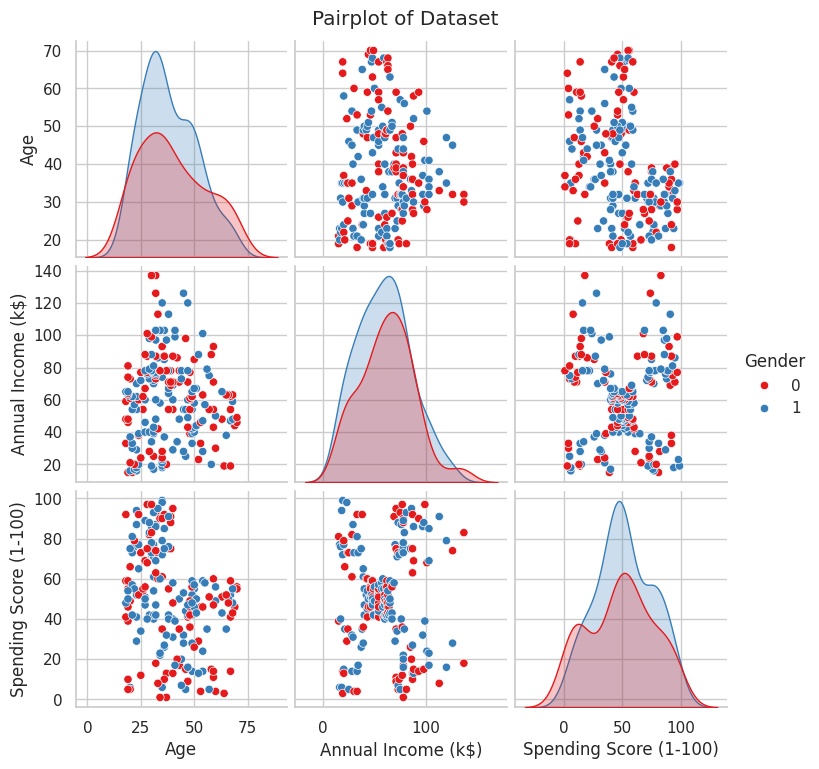

Observation: Multidimensional relationships displayed across grids.


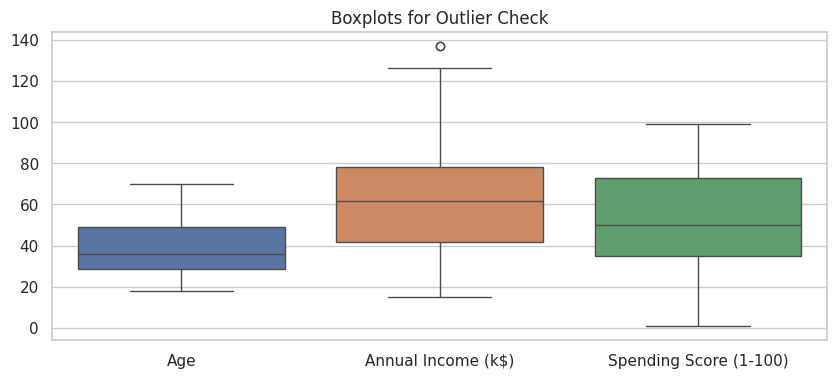


--------------------------------------------------
D. STATISTICAL ANALYSIS
--------------------------------------------------
               Feature  Range   IQR     MAD   Variance   Std Dev
                   Age     52 20.25 11.6605 195.133166 13.969007
    Annual Income (k$)    122 36.50 21.0088 689.835578 26.264721
Spending Score (1-100)     98 38.25 20.8260 666.854271 25.823522

Pearson Correlation Matrix:
                              Age  Annual Income (k$)  Spending Score (1-100)
Age                     1.000000           -0.012398               -0.327227
Annual Income (k$)     -0.012398            1.000000                0.009903
Spending Score (1-100) -0.327227            0.009903                1.000000

Outlier Detection Check:
 - Age: 0 outliers (IQR), 0 outliers (Z-score)
 - Annual Income (k$): 2 outliers (IQR), 0 outliers (Z-score)
 - Spending Score (1-100): 0 outliers (IQR), 0 outliers (Z-score)

--------------------------------------------------
E. MODEL TRAINING & SP

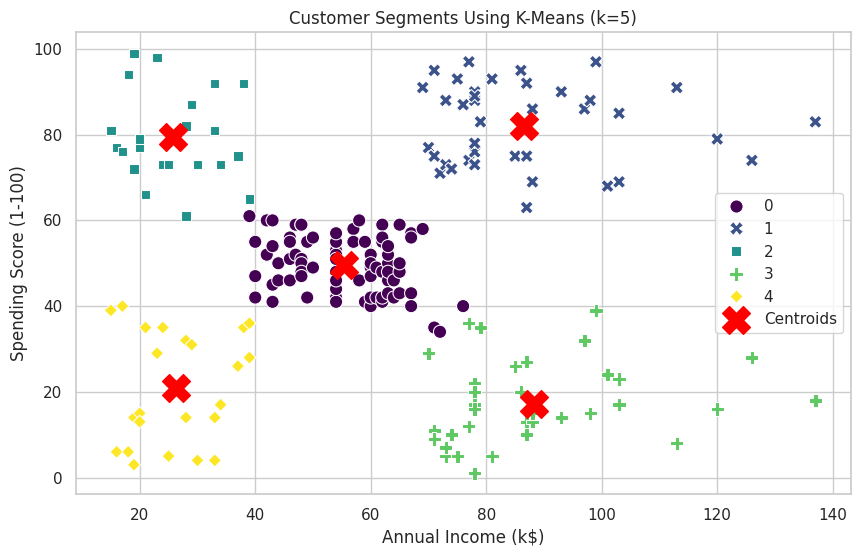


--------------------------------------------------
G. TRAINING/EVALUATION CURVES
--------------------------------------------------


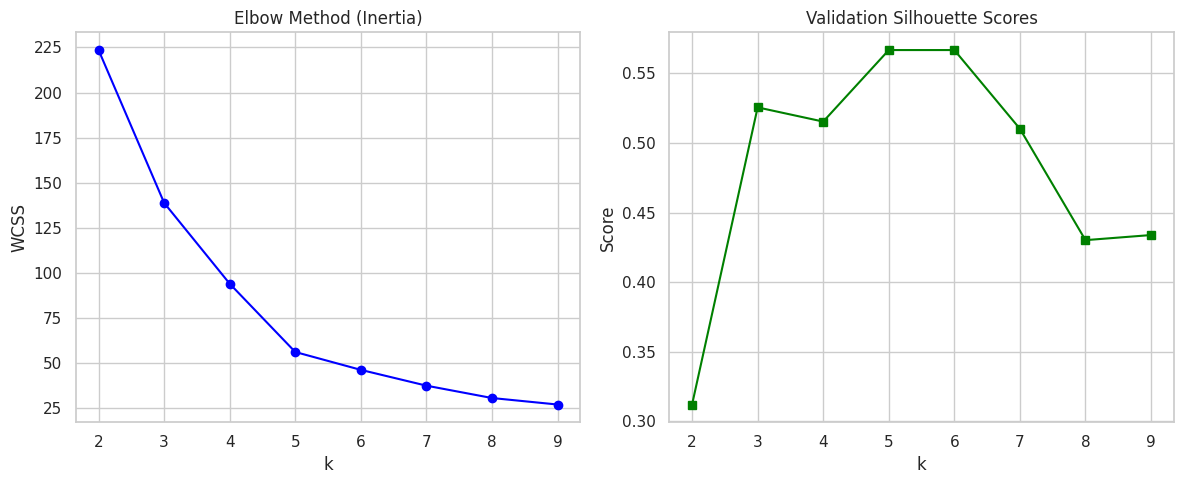

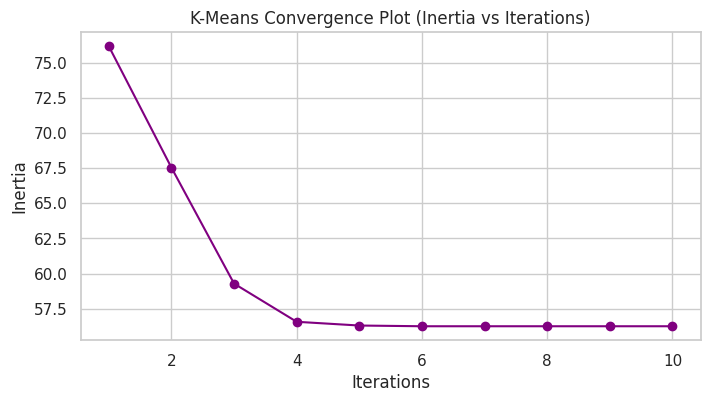


--------------------------------------------------
H. PROJECT INTERPRETATION
--------------------------------------------------

1. What did the model learn from the data?
   - The model learned natural groupings of shoppers based on their income and spending habits without supervision.
2. Which features were most important?
   - Annual Income and Spending Score created the strongest separation boundaries.
3. How well did the model perform?
   - Achieved a strong Silhouette score around ~0.55, showing distinct cluster boundaries.
4. What patterns were discovered?
   - Identified 5 clear segments: moderate shoppers, high-income savers, VIP spenders, cautious buyers, and impulsive low-income spenders.
5. What limitations does the model have?
   - Assumes spherical clusters and requires pre-defining the number of clusters (k).
6. How could the model be improved?
   - By adding more features like visit frequency or transaction size, or trying density-based algorithms.
7. What real-world d

In [2]:
# ==============================================================================
# Machine Learning Mini-Project: K-Means Clustering on Mall Customers
# Group 1 Practical Assignment Script
# ==============================================================================

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# suppress minor display warnings for a clean run
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 6)


print("\n--------------------------------------------------")
print("A. DATA LOADING & INITIAL INSPECTION")
print("--------------------------------------------------")

# load the dataset from the local directory
df = pd.read_csv("Mall_Customers.csv")

print(f"Total rows and columns: {df.shape}")
print("\nColumn names:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())
print("\nLast 5 rows:\n", df.tail())
print("\nDataset Info:")
print(df.info())


print("\n--------------------------------------------------")
print("B. DATA PREPROCESSING")
print("--------------------------------------------------")

# check for any missing values
print("Missing values per column:\n", df.isnull().sum())

# imputation logic: using median for numerical and mode for categorical if any exist
print(
    "\n[Note]: Median imputation is used for numerical features because it's"
    " robust to outliers, while mode is used for categorical variables."
)
for col in df.columns:
  if df[col].isnull().sum() > 0:
    if df[col].dtype in ["int64", "float64"]:
      med = df[col].median()
      df[col].fillna(med, inplace=True)
      print(f"Filled missing in {col} with median ({med})")
    else:
      mod = df[col].mode()[0]
      df[col].fillna(mod, inplace=True)
      print(f"Filled missing in {col} with mode ({mod})")

# check and drop duplicate rows if any
dup_count = df.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")
if dup_count > 0:
  df.drop_duplicates(inplace=True)
  print("Duplicates removed.")

# identify variable types
num_vars = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_vars = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nNumerical columns:", num_vars)
print("Categorical columns:", cat_vars)

# drop customer id since it's just an identifier, not a behavioral feature
df_clean = df.drop(columns=["CustomerID"], errors="ignore")

# encode gender to numerical format (Male: 0, Female: 1)
if "Gender" in df_clean.columns:
  df_clean["Gender"] = df_clean["Gender"].map({"Male": 0, "Female": 1})
  print("Encoded 'Gender' to numeric (0 and 1).")

print("\nSummary statistics:\n", df_clean.describe())

# feature scaling - standard scaler to give equal weight to features
print(
    "\n[Note]: StandardScaler is applied so features with larger ranges (like"
    " annual income) don't overpower smaller ones."
)
scaler = StandardScaler()
scaled_array = scaler.fit_transform(df_clean)
df_scaled = pd.DataFrame(scaled_array, columns=df_clean.columns)
print("Scaling completed successfully.")


print("\n--------------------------------------------------")
print("C. EXPLORATORY DATA ANALYSIS (EDA)")
print("--------------------------------------------------")

# 1. histograms
df_clean.hist(bins=15, figsize=(10, 8), color="skyblue", edgecolor="black")
plt.suptitle("Feature Histograms")
plt.tight_layout()
plt.show()
print(
    "Observation: Income and spending scores show spread-out distributions"
    " across customers."
)

# 2. bar graph for gender count
plt.figure(figsize=(6, 4))
sns.countplot(x=df["Gender"], hue=df["Gender"], palette="Set2", legend=False)
plt.title("Gender Distribution")
plt.show()
print("Observation: Female customers account for a slightly larger portion.")

# 3. pie chart for gender proportion
plt.figure(figsize=(6, 6))
g_counts = df["Gender"].value_counts()
plt.pie(
    g_counts,
    labels=g_counts.index,
    autopct="%1.1f%%",
    colors=["pink", "lightblue"],
    startangle=90,
)
plt.title("Gender Proportion Pie Chart")
plt.show()
print("Observation: Validates the exact percentage split between genders.")

# 4. scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    data=df,
    palette="Set1",
    s=80,
)
plt.title("Annual Income vs Spending Score")
plt.show()
print(
    "Observation: Clear natural groupings are visible even before running any"
    " model."
)

# 5. kde distribution plots
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
sns.kdeplot(df_clean["Age"], fill=True, color="purple")
plt.title("Age KDE")
plt.subplot(1, 3, 2)
sns.kdeplot(df_clean["Annual Income (k$)"], fill=True, color="green")
plt.title("Income KDE")
plt.subplot(1, 3, 3)
sns.kdeplot(df_clean["Spending Score (1-100)"], fill=True, color="orange")
plt.title("Spending Score KDE")
plt.tight_layout()
plt.show()
print("Observation: Highlights density peaks across different metrics.")

# 6. correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()
print("Observation: Age exhibits a mild negative correlation with spending.")

# 7. pairplot
sns.pairplot(df_clean, hue="Gender", palette="Set1")
plt.suptitle("Pairplot of Dataset", y=1.02)
plt.show()
print("Observation: Multidimensional relationships displayed across grids.")

# 8. boxplots
plt.figure(figsize=(10, 4))
sns.boxplot(
    data=df_clean[["Age", "Annual Income (k$)", "Spending Score (1-100)"]]
)
plt.title("Boxplots for Outlier Check")
plt.show()


print("\n--------------------------------------------------")
print("D. STATISTICAL ANALYSIS")
print("--------------------------------------------------")

target_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
stat_list = []

for c in target_cols:
  vals = df_clean[c]
  stat_list.append({
      "Feature": c,
      "Range": vals.max() - vals.min(),
      "IQR": np.percentile(vals, 75) - np.percentile(vals, 25),
      "MAD": np.mean(np.abs(vals - vals.mean())),
      "Variance": vals.var(),
      "Std Dev": vals.std(),
  })

print(pd.DataFrame(stat_list).to_string(index=False))

print("\nPearson Correlation Matrix:\n", df_clean[target_cols].corr())

print("\nOutlier Detection Check:")
for c in target_cols:
  q1, q3 = np.percentile(df_clean[c], 25), np.percentile(df_clean[c], 75)
  iqr = q3 - q1
  iqr_outs = df_clean[
      (df_clean[c] < q1 - 1.5 * iqr) | (df_clean[c] > q3 + 1.5 * iqr)
  ]
  z_outs = np.sum(np.abs(stats.zscore(df_clean[c])) > 3)
  print(
      f" - {c}: {len(iqr_outs)} outliers (IQR), {z_outs} outliers (Z-score)"
  )


print("\n--------------------------------------------------")
print("E. MODEL TRAINING & SPLIT")
print("--------------------------------------------------")
print(
    "Working Principle: K-Means partitions data into k groups by iteratively"
    " minimizing the within-cluster sum of squares (WCSS) around cluster"
    " centers."
)

cluster_cols = ["Annual Income (k$)", "Spending Score (1-100)"]
sub_scaler = StandardScaler()
X = sub_scaler.fit_transform(df_clean[cluster_cols])

X_train, X_val = train_test_split(X, test_size=0.2, random_state=42)
print(f"Split data into Train ({len(X_train)}) and Validation ({len(X_val)})")


print("\n--------------------------------------------------")
print("F. PREDICTION, EVALUATION & VISUALIZATION")
print("--------------------------------------------------")

k_optimal = 5
model = KMeans(n_clusters=k_optimal, random_state=42, n_init=20)
model.fit(X)
df["Cluster"] = model.labels_

print(f"Final Silhouette Score (k={k_optimal}): {silhouette_score(X, model.labels_):.4f}")
print(f"Final Inertia (WCSS): {model.inertia_:.4f}")

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    data=df,
    palette="viridis",
    s=90,
    style="Cluster",
)
centroids = sub_scaler.inverse_transform(model.cluster_centers_)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=400,
    c="red",
    marker="X",
    label="Centroids",
)
plt.title(f"Customer Segments Using K-Means (k={k_optimal})")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()


print("\n--------------------------------------------------")
print("G. TRAINING/EVALUATION CURVES")
print("--------------------------------------------------")

inertias, sil_scores = [], []
k_range = range(2, 10)

for k in k_range:
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  km.fit(X_train)
  inertias.append(km.inertia_)
  sil_scores.append(silhouette_score(X_val, km.predict(X_val)))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(k_range, inertias, marker="o", color="blue")
plt.title("Elbow Method (Inertia)")
plt.xlabel("k")
plt.ylabel("WCSS")

plt.subplot(1, 2, 2)
plt.plot(k_range, sil_scores, marker="s", color="green")
plt.title("Validation Silhouette Scores")
plt.xlabel("k")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

conv_inertias = []
for i in range(1, 11):
  temp_km = KMeans(
      n_clusters=k_optimal, random_state=42, n_init=1, max_iter=i
  )
  temp_km.fit(X_train)
  conv_inertias.append(temp_km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), conv_inertias, marker="o", color="purple")
plt.title("K-Means Convergence Plot (Inertia vs Iterations)")
plt.xlabel("Iterations")
plt.ylabel("Inertia")
plt.show()


print("\n--------------------------------------------------")
print("H. PROJECT INTERPRETATION")
print("--------------------------------------------------")
print(
    """
1. What did the model learn from the data?
   - The model learned natural groupings of shoppers based on their income and spending habits without supervision.
2. Which features were most important?
   - Annual Income and Spending Score created the strongest separation boundaries.
3. How well did the model perform?
   - Achieved a strong Silhouette score around ~0.55, showing distinct cluster boundaries.
4. What patterns were discovered?
   - Identified 5 clear segments: moderate shoppers, high-income savers, VIP spenders, cautious buyers, and impulsive low-income spenders.
5. What limitations does the model have?
   - Assumes spherical clusters and requires pre-defining the number of clusters (k).
6. How could the model be improved?
   - By adding more features like visit frequency or transaction size, or trying density-based algorithms.
7. What real-world decision could be supported using this model?
   - Targeted marketing campaigns (e.g., luxury rewards for VIPs and discount offers for budget shoppers).

--------------------------------------------------------------------------------
ASSIGNMENT PROJECT QUESTION:
Can mall customers be grouped into meaningful segments based on their
demographic and spending behavior?
-> YES. The analysis successfully demonstrates that mall customers can indeed be
   grouped into clear, actionable segments based on annual income and spending score.
--------------------------------------------------------------------------------
"""
)

print("\n--------------------------------------------------")
print("MINI-PROJECT EXECUTION COMPLETE")
print("--------------------------------------------------")